
# Credit Card Fraud Detection & Decision Optimization Platform

**Objective:** Build an end-to-end credit card fraud detection system that identifies suspicious transactions, evaluates the financial consequences of fraud decisions, serves predictions through a working API, and monitors model behavior.

**Technology Stack:** Python, Pandas, NumPy, Scikit-learn, XGBoost, Matplotlib, Seaborn, FastAPI, SQLite, SQL, Pytest, Jupyter Notebook.

**Dataset:** Kaggle Credit Card Fraud Detection dataset.

---



## 1. Dataset Loading and Initial Inspection


In [1]:

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path.home() / "Desktop" / "credit-card-fraud-detection"
DATA_PATH = PROJECT_DIR / "data" / "creditcard.csv"

print("Project directory:", PROJECT_DIR)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())


Project directory: C:\Users\dell\Desktop\credit-card-fraud-detection
Dataset path: C:\Users\dell\Desktop\credit-card-fraud-detection\data\creditcard.csv
Dataset exists: True


In [2]:

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset loaded successfully.
Number of rows: 284807
Number of columns: 31


In [3]:

df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:

print("Column names:")
print(df.columns.tolist())

print("\nTotal columns:", len(df.columns))


Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Total columns: 31


In [5]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [6]:

missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())
print("\nColumns with missing values:")
print(missing_values[missing_values > 0])


Total missing values: 0

Columns with missing values:
Series([], dtype: int64)


In [7]:

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print(
    "Percentage of rows that are duplicates:",
    round((duplicate_count / len(df)) * 100, 4),
    "%"
)


Number of duplicate rows: 1081
Percentage of rows that are duplicates: 0.3796 %


In [8]:

class_counts = df["Class"].value_counts().sort_index()

print("Transaction counts by class:")
print(class_counts)

print("\nTransaction percentages by class:")
print((df["Class"].value_counts(normalize=True).sort_index() * 100).round(4))


Transaction counts by class:
Class
0    284315
1       492
Name: count, dtype: int64

Transaction percentages by class:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


In [9]:

print("Transaction Amount Summary:")
print(df["Amount"].describe().round(2))

print("\nZero-amount transactions:", (df["Amount"] == 0).sum())
print("Negative-amount transactions:", (df["Amount"] < 0).sum())


Transaction Amount Summary:
count    284807.00
mean         88.35
std         250.12
min           0.00
25%           5.60
50%          22.00
75%          77.16
max       25691.16
Name: Amount, dtype: float64

Zero-amount transactions: 1825
Negative-amount transactions: 0


In [10]:

amount_by_class = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

amount_by_class.index = ["Legitimate (0)", "Fraudulent (1)"]

display(amount_by_class)


,count,mean,median,min,max,std
Legitimate (0),284315,88.29,22.00,0.0,25691.16,250.11
Fraudulent (1),492,122.21,9.25,0.0,2125.87,256.68


In [11]:

print("Time column summary:")
print(df["Time"].describe().round(2))

print("\nEarliest recorded time:", df["Time"].min(), "seconds")
print("Latest recorded time:", df["Time"].max(), "seconds")
print(
    "Approximate observation window:",
    round((df["Time"].max() - df["Time"].min()) / 3600, 2),
    "hours"
)


Time column summary:
count    284807.00
mean      94813.86
std       47488.15
min           0.00
25%       54201.50
50%       84692.00
75%      139320.50
max      172792.00
Name: Time, dtype: float64

Earliest recorded time: 0.0 seconds
Latest recorded time: 172792.0 seconds
Approximate observation window: 48.0 hours


In [12]:

print("Unique target labels:", sorted(df["Class"].unique()))

unexpected_labels = df.loc[~df["Class"].isin([0, 1]), "Class"]
print("Number of unexpected target labels:", len(unexpected_labels))


Unique target labels: [np.int64(0), np.int64(1)]
Number of unexpected target labels: 0


In [13]:

duplicate_rows = df[df.duplicated(keep=False)]

print("Rows involved in duplicate groups:", len(duplicate_rows))
print("\nClass distribution among these rows:")
print(duplicate_rows["Class"].value_counts().sort_index())

print("\nDuplicate rows by class (including repeated occurrences):")
print(duplicate_rows.groupby("Class").size())


Rows involved in duplicate groups: 1854

Class distribution among these rows:
Class
0    1822
1      32
Name: count, dtype: int64

Duplicate rows by class (including repeated occurrences):
Class
0    1822
1      32
dtype: int64


In [14]:

feature_columns = [col for col in df.columns if col.startswith("V")]

print("Non-finite values across numeric columns:",
      int((~np.isfinite(df.select_dtypes(include=np.number))).sum().sum()))

print("Non-finite values in Time:", int((~np.isfinite(df["Time"])).sum()))
print("Non-finite values in Amount:", int((~np.isfinite(df["Amount"])).sum()))
print("Non-finite values in V1–V28:",
      int((~np.isfinite(df[feature_columns])).sum().sum()))

print("Negative Time values:", int((df["Time"] < 0).sum()))


Non-finite values across numeric columns: 0
Non-finite values in Time: 0
Non-finite values in Amount: 0
Non-finite values in V1–V28: 0
Negative Time values: 0



### Dataset Limitations

- **Severe class imbalance:** Fraudulent transactions account for approximately 0.173% of the dataset. Accuracy alone is therefore an inadequate measure of model performance.
- **Anonymized features:** V1–V28 are PCA-transformed variables. Their original business meanings are unavailable, so interpretations will focus on statistical relationships rather than assumed customer or merchant behavior.
- **Short observation period:** The dataset covers approximately 48 hours of transactions from September 2013. It cannot establish long-term model stability or represent current fraud patterns reliably.
- **Duplicate records:** The initial audit identified 1,081 duplicate occurrences using `duplicated()` and 1,854 rows belonging to duplicate groups using `duplicated(keep=False)`. These records require investigation before any removal decision.
- **Zero transaction amounts:** There are 1,825 transactions with an amount of zero. These will be investigated rather than automatically removed.
- **Historical data:** The dataset is historical and does not represent a live transaction stream. API and monitoring demonstrations will therefore use controlled test inputs or batches.
- **Simulated financial estimates:** Any estimated fraud losses, false-decline costs, or potential savings will depend on explicit assumptions and will not be presented as actual realized outcomes.



## 2. Data Cleaning and Leakage-Safe Preparation

This section investigates duplicate transactions, validates data types and values, and prepares the dataset for chronological model development. Duplicate records will be investigated rather than automatically removed. Training, validation, and test data will be separated by transaction time to reduce temporal leakage.


In [15]:

print("Dataset is sorted by Time:", df["Time"].is_monotonic_increasing)
print("Number of rows out of chronological order:",
      int((df["Time"].diff().dropna() < 0).sum()))


Dataset is sorted by Time: True
Number of rows out of chronological order: 0


In [16]:

print("Data types:")
display(df.dtypes.to_frame(name="Data type"))

print("\nNumeric columns:", len(df.select_dtypes(include=np.number).columns))
print("Non-numeric columns:", len(df.select_dtypes(exclude=np.number).columns))


Data types:


,Data type
Time,float64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64



Numeric columns: 31
Non-numeric columns: 0


In [17]:

duplicate_mask = df.duplicated(keep=False)

print("Total rows:", len(df))
print("Rows belonging to duplicate groups:", int(duplicate_mask.sum()))
print("Unique rows after keeping the first occurrence:",
      int((~df.duplicated()).sum()))

print("\nDuplicate-group rows by target class:")
display(df.loc[duplicate_mask, "Class"].value_counts().sort_index().to_frame("Rows"))


Total rows: 284807
Rows belonging to duplicate groups: 1854
Unique rows after keeping the first occurrence: 283726

Duplicate-group rows by target class:


,Rows
Class,
0,1822
1,32


In [18]:

duplicate_examples = (
    df.loc[duplicate_mask]
      .sort_values(["Time", "Amount", "Class"])
      .head(10)
)

display(duplicate_examples)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


In [19]:

checks = {
    "Missing values": int(df.isnull().sum().sum()),
    "Infinite numeric values": int(
        (~np.isfinite(df.select_dtypes(include=np.number))).sum().sum()
    ),
    "Negative Time values": int((df["Time"] < 0).sum()),
    "Negative Amount values": int((df["Amount"] < 0).sum()),
    "Zero Amount values": int((df["Amount"] == 0).sum()),
    "Unexpected Class labels": int((~df["Class"].isin([0, 1])).sum()),
}

display(pd.Series(checks, name="Count").to_frame())


,Count
Missing values,0
Infinite numeric values,0
Negative Time values,0
Negative Amount values,0
Zero Amount values,1825
Unexpected Class labels,0


In [20]:

duplicate_rows = df.loc[df.duplicated(keep=False)].copy()

duplicate_group_summary = (
    duplicate_rows.groupby(["Time", "Amount", "Class"])
    .size()
    .reset_index(name="Rows in group")
    .sort_values("Rows in group", ascending=False)
)

print("Number of duplicate groups based on all columns:")
print(df.duplicated().sum())

print("\nLargest exact-duplicate groups:")
display(duplicate_group_summary.head(10))


Number of duplicate groups based on all columns:
1081

Largest exact-duplicate groups:


,Time,Amount,Class,Rows in group
718,163152.0,7.56,0,18
717,163152.0,1.51,0,18
145,43153.0,0.76,0,9
760,170731.0,0.76,0,9
280,68207.0,1.00,1,6
286,68780.0,336.70,0,5
283,68780.0,281.47,0,5
249,64947.0,5.96,0,5
252,64947.0,34.27,0,5
287,68780.0,664.32,0,5


In [21]:

zero_amount_summary = (
    df.assign(Zero_Amount=df["Amount"].eq(0))
      .groupby(["Class", "Zero_Amount"])
      .size()
      .unstack(fill_value=0)
)

zero_amount_summary.index = ["Legitimate (0)", "Fraudulent (1)"]
zero_amount_summary.columns = ["Non-zero amount", "Zero amount"]

display(zero_amount_summary)


,Non-zero amount,Zero amount
Legitimate (0),282517,1798
Fraudulent (1),465,27


In [22]:

print("First transaction time:", df["Time"].iloc[0])
print("Last transaction time:", df["Time"].iloc[-1])

print("\nTarget distribution in chronological order:")
display(
    df.groupby(pd.cut(df["Time"], bins=10, include_lowest=True))["Class"]
      .agg(["count", "sum", "mean"])
      .rename(columns={
          "count": "Transactions",
          "sum": "Fraud cases",
          "mean": "Fraud rate"
      })
      .assign(Fraud_rate_percent=lambda x: (x.pop("Fraud rate") * 100).round(4))
)


First transaction time: 0.0
Last transaction time: 172792.0

Target distribution in chronological order:


,Transactions,Fraud cases,Fraud_rate_percent
Time,,,
"(-172.793, 17279.2]",10510,42,0.3996
"(17279.2, 34558.4]",16955,48,0.2831
"(34558.4, 51837.6]",38526,79,0.2051
"(51837.6, 69116.8]",38550,63,0.1634
"(69116.8, 86396.0]",40243,49,0.1218
"(86396.0, 103675.2]",10145,68,0.6703
"(103675.2, 120954.4]",17161,11,0.0641
"(120954.4, 138233.6]",38951,34,0.0873
"(138233.6, 155512.8]",40779,66,0.1618



### Data Quality Decisions and Chronological Split

- No missing, infinite, or invalid target values were detected.
- Duplicate records will be retained for the initial modelling dataset. Their presence will be documented as a limitation.
- Zero-amount transactions will be retained because zero amounts occur in both legitimate and fraudulent transactions.
- The dataset will be split chronologically into training (70%), validation (15%), and test (15%) sets. The training set will be used for model fitting, the validation set for model and threshold selection, and the test set for final evaluation.
- Any learned preprocessing or resampling will be fitted or applied using training data only.


In [23]:

# Create chronological 70% / 15% / 15% splits.
n = len(df)
train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
validation_df = df.iloc[train_end:validation_end].copy()
test_df = df.iloc[validation_end:].copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(validation_df))
print("Test rows:", len(test_df))
print("Total rows:", len(train_df) + len(validation_df) + len(test_df))


Training rows: 199364
Validation rows: 42721
Test rows: 42722
Total rows: 284807


In [24]:

# Verify the time boundaries of each split.
split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Rows": [len(train_df), len(validation_df), len(test_df)],
    "Start Time": [
        train_df["Time"].min(),
        validation_df["Time"].min(),
        test_df["Time"].min()
    ],
    "End Time": [
        train_df["Time"].max(),
        validation_df["Time"].max(),
        test_df["Time"].max()
    ],
    "Fraud Cases": [
        int(train_df["Class"].sum()),
        int(validation_df["Class"].sum()),
        int(test_df["Class"].sum())
    ],
    "Fraud Rate (%)": [
        round(train_df["Class"].mean() * 100, 4),
        round(validation_df["Class"].mean() * 100, 4),
        round(test_df["Class"].mean() * 100, 4)
    ]
})

display(split_summary)


,Split,Rows,Start Time,End Time,Fraud Cases,Fraud Rate (%)
0,Training,199364,0.0,132928.0,384,0.1926
1,Validation,42721,132929.0,151328.0,56,0.1311
2,Test,42722,151328.0,172792.0,52,0.1217



## 3. Exploratory Data Analysis (EDA)

This section explores the distribution of fraudulent and legitimate transactions, transaction amounts, fraud rates across time intervals, and relationships between transaction features and the target variable. Because the dataset is severely imbalanced, the analysis will focus on fraud counts, rates, and patterns rather than accuracy or raw transaction volume alone.


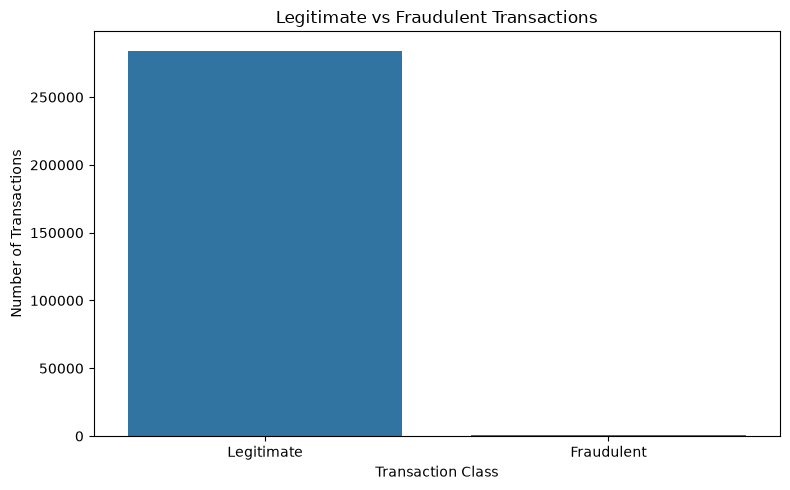

Fraud percentage: 0.1727 %


In [25]:

import matplotlib.pyplot as plt
import seaborn as sns

class_counts = df["Class"].value_counts().sort_index()
class_labels = ["Legitimate", "Fraudulent"]

plt.figure(figsize=(8, 5))
sns.barplot(x=class_labels, y=class_counts.values)
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

print("Fraud percentage:", round(df["Class"].mean() * 100, 4), "%")


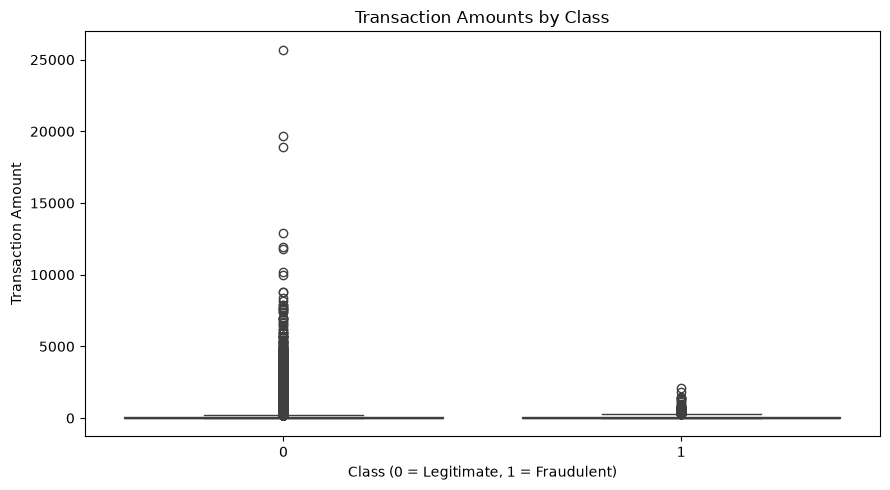

,count,mean,median,std,min,max
Class,,,,,,
0,284315,88.29,22.00,250.11,0.0,25691.16
1,492,122.21,9.25,256.68,0.0,2125.87


In [26]:

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Class", y="Amount")
plt.title("Transaction Amounts by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()

display(
    df.groupby("Class")["Amount"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .round(2)
)


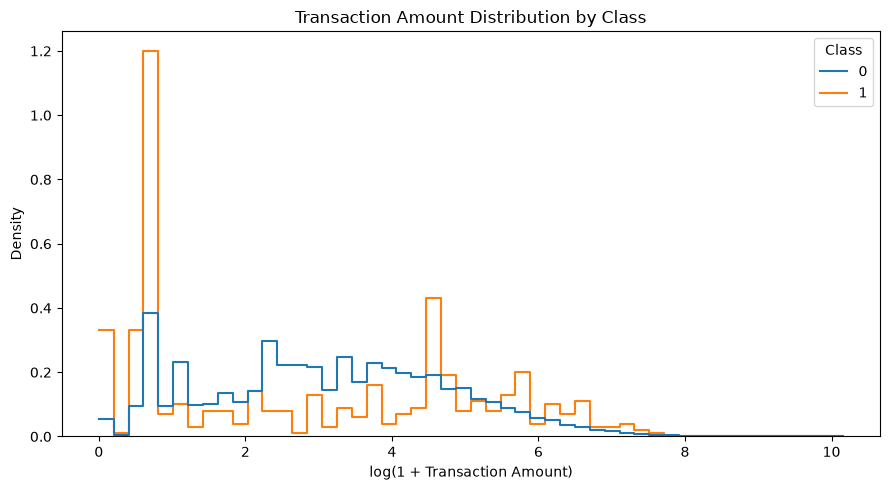

In [27]:

amount_plot_df = df[["Amount", "Class"]].copy()
amount_plot_df["Log_Amount"] = np.log1p(amount_plot_df["Amount"])

plt.figure(figsize=(9, 5))
sns.histplot(
    data=amount_plot_df,
    x="Log_Amount",
    hue="Class",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)
plt.title("Transaction Amount Distribution by Class")
plt.xlabel("log(1 + Transaction Amount)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


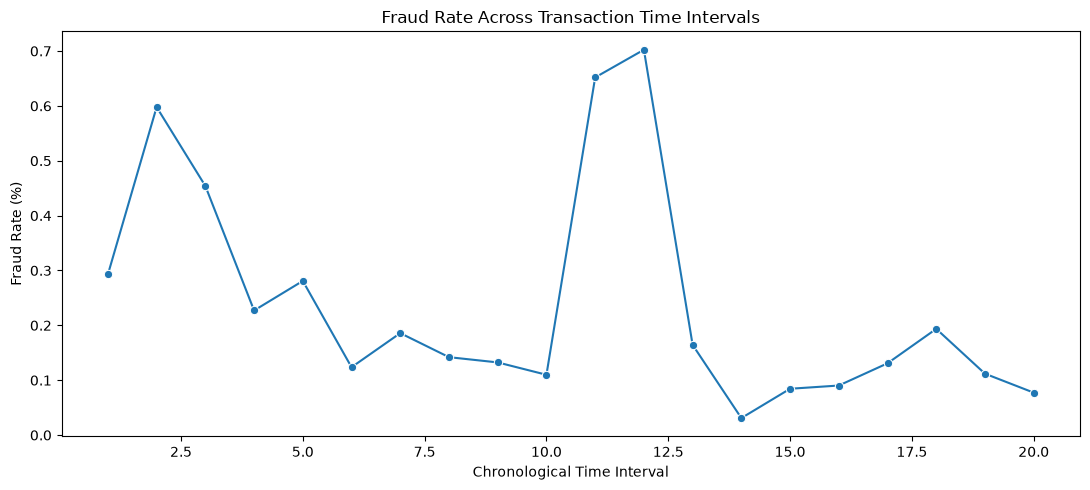

,Interval,count,sum,Fraud Rate (%)
0,1,6830,20,0.2928
1,2,3680,22,0.5978
2,3,4185,19,0.4540
3,4,12770,29,0.2271
4,5,19932,56,0.2810
5,6,18594,23,0.1237
6,7,18833,35,0.1858
7,8,19717,28,0.1420
8,9,21140,28,0.1325
9,10,19103,21,0.1099


In [28]:

time_bins = pd.cut(df["Time"], bins=20, include_lowest=True)

fraud_over_time = (
    df.groupby(time_bins, observed=False)["Class"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

fraud_over_time["Interval"] = range(1, len(fraud_over_time) + 1)
fraud_over_time["Fraud Rate (%)"] = fraud_over_time["mean"] * 100

plt.figure(figsize=(11, 5))
sns.lineplot(data=fraud_over_time, x="Interval", y="Fraud Rate (%)", marker="o")
plt.title("Fraud Rate Across Transaction Time Intervals")
plt.xlabel("Chronological Time Interval")
plt.ylabel("Fraud Rate (%)")
plt.tight_layout()
plt.show()

display(fraud_over_time[["Interval", "count", "sum", "Fraud Rate (%)"]].round(4))


,Legitimate Mean,Fraudulent Mean,Absolute Mean Difference
V3,0.0122,-7.0333,7.0455
V14,0.0121,-6.9717,6.9838
V17,0.0115,-6.6658,6.6774
V12,0.0108,-6.2594,6.2702
V10,0.0098,-5.6769,5.6867
V7,0.0096,-5.5687,5.5784
V1,0.0083,-4.7719,4.7802
V4,-0.0079,4.5420,4.5499
V16,0.0072,-4.1399,4.1471
V11,-0.0066,3.8002,3.8067


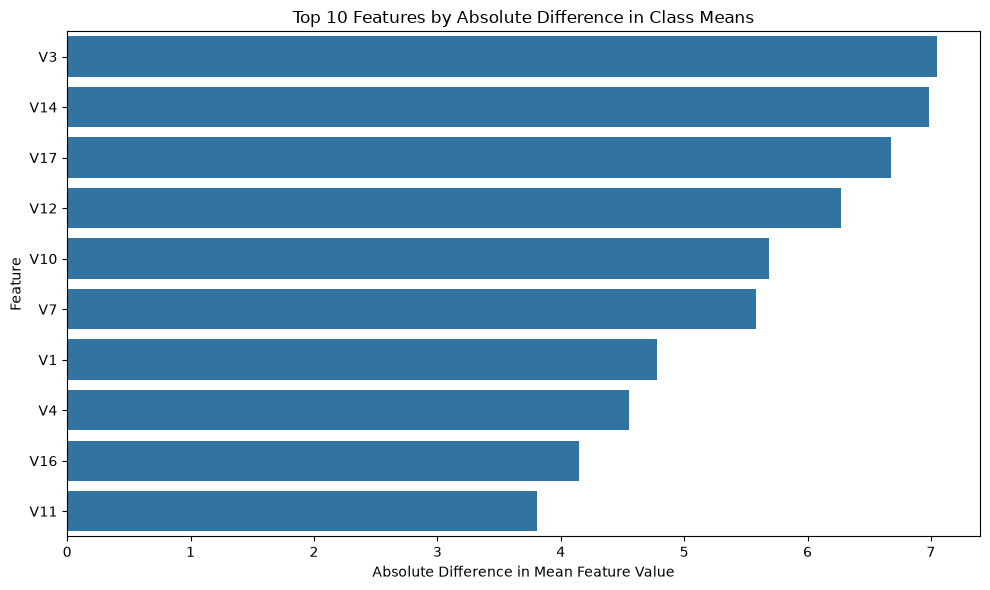

In [29]:

feature_columns = [f"V{i}" for i in range(1, 29)]

feature_means = df.groupby("Class")[feature_columns].mean().T
feature_means.columns = ["Legitimate Mean", "Fraudulent Mean"]
feature_means["Absolute Mean Difference"] = (
    feature_means["Fraudulent Mean"] - feature_means["Legitimate Mean"]
).abs()

top_features = feature_means.sort_values(
    "Absolute Mean Difference", ascending=False
).head(10)

display(top_features.round(4))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_features.reset_index(),
    x="Absolute Mean Difference",
    y="index"
)
plt.title("Top 10 Features by Absolute Difference in Class Means")
plt.xlabel("Absolute Difference in Mean Feature Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [30]:

# Save all five Step 3 charts in reports/figures
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Chart 1: Class distribution
plt.figure(figsize=(8, 5))
sns.barplot(x=["Legitimate", "Fraudulent"],
            y=df["Class"].value_counts().sort_index().values)
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_class_distribution.png", dpi=300, bbox_inches="tight")
plt.close()

# Chart 2: Transaction amounts by class
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Class", y="Amount")
plt.title("Transaction Amounts by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_amount_boxplot.png", dpi=300, bbox_inches="tight")
plt.close()

# Chart 3: Log-transformed amount distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=amount_plot_df, x="Log_Amount", hue="Class",
             bins=50, stat="density", common_norm=False,
             element="step", fill=False)
plt.title("Transaction Amount Distribution by Class")
plt.xlabel("log(1 + Transaction Amount)")
plt.ylabel("Density")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_log_amount_distribution.png", dpi=300, bbox_inches="tight")
plt.close()

# Chart 4: Fraud rate over time
plt.figure(figsize=(11, 5))
sns.lineplot(data=fraud_over_time, x="Interval",
             y="Fraud Rate (%)", marker="o")
plt.title("Fraud Rate Across Transaction Time Intervals")
plt.xlabel("Chronological Time Interval")
plt.ylabel("Fraud Rate (%)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_fraud_rate_over_time.png", dpi=300, bbox_inches="tight")
plt.close()

# Chart 5: Top features by difference in class means
plt.figure(figsize=(10, 6))
sns.barplot(data=top_features.reset_index(),
            x="Absolute Mean Difference", y="index")
plt.title("Top 10 Features by Absolute Difference in Class Means")
plt.xlabel("Absolute Difference in Mean Feature Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_top_feature_mean_differences.png",
            dpi=300, bbox_inches="tight")
plt.close()

print("Saved chart files:")
for file_path in sorted(FIGURES_DIR.glob("*.png")):
    print(file_path.name, "-", round(file_path.stat().st_size / 1024, 1), "KB")


Saved chart files:
01_class_distribution.png - 62.7 KB
02_amount_boxplot.png - 76.2 KB
03_log_amount_distribution.png - 71.6 KB
04_fraud_rate_over_time.png - 165.5 KB
05_top_feature_mean_differences.png - 82.0 KB



## 4. Model Development

This section establishes a simple baseline and trains fraud-classification models using the chronological training and validation datasets. The models will include Dummy Classifier, Logistic Regression, Random Forest, and XGBoost. Any learned preprocessing will be fitted on training data only, and the test set will remain untouched until final evaluation.


In [31]:

# Separate predictors (X) from the fraud label (y).
# Keep the original chronological splits unchanged.

X_train = train_df.drop(columns=["Class"]).copy()
y_train = train_df["Class"].copy()

X_validation = validation_df.drop(columns=["Class"]).copy()
y_validation = validation_df["Class"].copy()

X_test = test_df.drop(columns=["Class"]).copy()
y_test = test_df["Class"].copy()

print("Training features:", X_train.shape)
print("Validation features:", X_validation.shape)
print("Test features:", X_test.shape)

print("\nTraining fraud cases:", int(y_train.sum()))
print("Validation fraud cases:", int(y_validation.sum()))
print("Test fraud cases:", int(y_test.sum()))


Training features: (199364, 30)
Validation features: (42721, 30)
Test features: (42722, 30)

Training fraud cases: 384
Validation fraud cases: 56
Test fraud cases: 52


In [32]:

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


In [33]:

dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_validation)
dummy_probabilities = dummy_model.predict_proba(X_validation)[:, 1]

print("Baseline model: Dummy Classifier")
print("Validation ROC-AUC:", round(roc_auc_score(y_validation, dummy_probabilities), 4))
print("Validation PR-AUC:", round(average_precision_score(y_validation, dummy_probabilities), 4))
print("Precision:", round(precision_score(y_validation, dummy_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_validation, dummy_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_validation, dummy_predictions, zero_division=0), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_validation, dummy_predictions))


Baseline model: Dummy Classifier
Validation ROC-AUC: 0.5
Validation PR-AUC: 0.0013
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Confusion matrix:
[[42665     0]
 [   56     0]]


In [34]:

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_validation)
logistic_probabilities = logistic_model.predict_proba(X_validation)[:, 1]

print("Model: Logistic Regression")
print("Validation ROC-AUC:", round(roc_auc_score(y_validation, logistic_probabilities), 4))
print("Validation PR-AUC:", round(average_precision_score(y_validation, logistic_probabilities), 4))
print("Precision:", round(precision_score(y_validation, logistic_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_validation, logistic_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_validation, logistic_predictions, zero_division=0), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_validation, logistic_predictions))


Model: Logistic Regression
Validation ROC-AUC: 0.9828
Validation PR-AUC: 0.8394
Precision: 0.053
Recall: 0.9286
F1-score: 0.1003

Confusion matrix:
[[41736   929]
 [    4    52]]


In [35]:

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_validation)
rf_probabilities = random_forest_model.predict_proba(X_validation)[:, 1]

print("Model: Random Forest")
print("Validation ROC-AUC:", round(roc_auc_score(y_validation, rf_probabilities), 4))
print("Validation PR-AUC:", round(average_precision_score(y_validation, rf_probabilities), 4))
print("Precision:", round(precision_score(y_validation, rf_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_validation, rf_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_validation, rf_predictions, zero_division=0), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_validation, rf_predictions))


Model: Random Forest
Validation ROC-AUC: 0.9775
Validation PR-AUC: 0.8751
Precision: 1.0
Recall: 0.75
F1-score: 0.8571

Confusion matrix:
[[42665     0]
 [   14    42]]


In [36]:

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(len(y_train) - int(y_train.sum())) / int(y_train.sum()),
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_validation)
xgb_probabilities = xgb_model.predict_proba(X_validation)[:, 1]

print("Model: XGBoost")
print("Validation ROC-AUC:", round(roc_auc_score(y_validation, xgb_probabilities), 4))
print("Validation PR-AUC:", round(average_precision_score(y_validation, xgb_probabilities), 4))
print("Precision:", round(precision_score(y_validation, xgb_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_validation, xgb_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_validation, xgb_predictions, zero_division=0), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_validation, xgb_predictions))


Model: XGBoost
Validation ROC-AUC: 0.9872
Validation PR-AUC: 0.8396
Precision: 0.7258
Recall: 0.8036
F1-score: 0.7627

Confusion matrix:
[[42648    17]
 [   11    45]]


In [37]:

models = {
    "Dummy Classifier": (dummy_predictions, dummy_probabilities),
    "Logistic Regression": (logistic_predictions, logistic_probabilities),
    "Random Forest": (rf_predictions, rf_probabilities),
    "XGBoost": (xgb_predictions, xgb_probabilities)
}

comparison_rows = []

for model_name, (predictions, probabilities) in models.items():
    tn, fp, fn, tp = confusion_matrix(
        y_validation, predictions, labels=[0, 1]
    ).ravel()

    comparison_rows.append({
        "Model": model_name,
        "ROC-AUC": roc_auc_score(y_validation, probabilities),
        "PR-AUC": average_precision_score(y_validation, probabilities),
        "Precision": precision_score(y_validation, predictions, zero_division=0),
        "Recall": recall_score(y_validation, predictions, zero_division=0),
        "F1-score": f1_score(y_validation, predictions, zero_division=0),
        "False Positives": fp,
        "Fraud Missed": fn,
        "Fraud Detected": tp
    })

model_comparison = pd.DataFrame(comparison_rows).set_index("Model")
display(model_comparison.round(4))


,ROC-AUC,PR-AUC,Precision,Recall,F1-score,False Positives,Fraud Missed,Fraud Detected
Model,,,,,,,,
Dummy Classifier,0.5000,0.0013,0.0000,0.0000,0.0000,0,56,0
Logistic Regression,0.9828,0.8394,0.0530,0.9286,0.1003,929,4,52
Random Forest,0.9775,0.8751,1.0000,0.7500,0.8571,0,14,42
XGBoost,0.9872,0.8396,0.7258,0.8036,0.7627,17,11,45


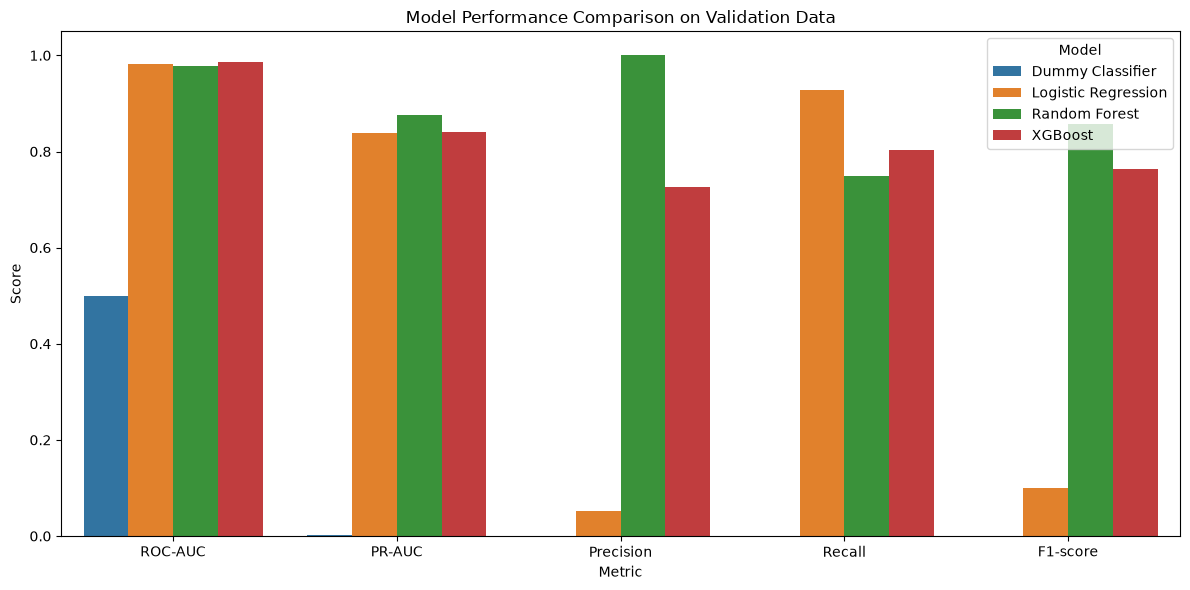

Saved: C:\Users\dell\Desktop\credit-card-fraud-detection\reports\figures\06_model_performance_comparison.png


In [38]:

comparison_plot = (
    model_comparison[["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1-score"]]
    .reset_index()
    .melt(id_vars="Model", var_name="Metric", value_name="Score")
)

plt.figure(figsize=(12, 6))
sns.barplot(data=comparison_plot, x="Metric", y="Score", hue="Model")
plt.title("Model Performance Comparison on Validation Data")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "06_model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Saved:", FIGURES_DIR / "06_model_performance_comparison.png")


## 5. Model Evaluation and Threshold Selection

This section evaluates fraud detection performance using precision, recall, F1-score, ROC-AUC, PR-AUC, and confusion matrices. Classification thresholds will be examined using validation data to understand the trade-off between missed fraud and false positives. The final model and threshold will be selected without using the test set, which will be reserved for final evaluation.

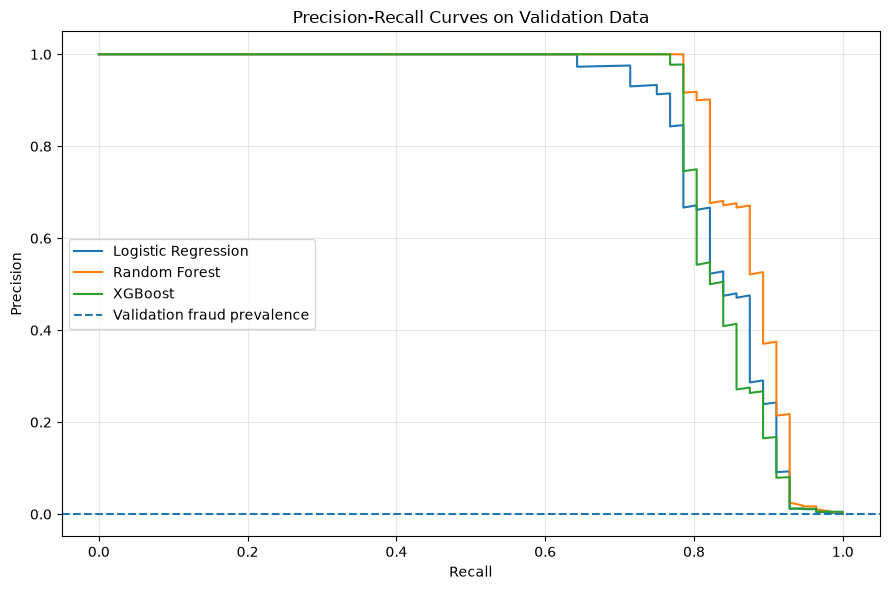

Saved: C:\Users\dell\Desktop\credit-card-fraud-detection\reports\figures\07_precision_recall_curves.png


In [39]:

from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay

plt.figure(figsize=(9, 6))

for model_name, probabilities in [
    ("Logistic Regression", logistic_probabilities),
    ("Random Forest", rf_probabilities),
    ("XGBoost", xgb_probabilities)
]:
    precision_values, recall_values, _ = precision_recall_curve(
        y_validation, probabilities
    )
    plt.plot(recall_values, precision_values, label=model_name)

plt.axhline(
    y=y_validation.mean(),
    linestyle="--",
    label="Validation fraud prevalence"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves on Validation Data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "07_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Saved:", FIGURES_DIR / "07_precision_recall_curves.png")


In [41]:

threshold_rows = []

for model_name, probabilities in [
    ("Logistic Regression", logistic_probabilities),
    ("Random Forest", rf_probabilities),
    ("XGBoost", xgb_probabilities)
]:
    for threshold in [0.10, 0.25, 0.50, 0.75, 0.90]:
        predictions = (probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_validation, predictions, labels=[0, 1]
        ).ravel()

        threshold_rows.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_validation, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_validation, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_validation, predictions, zero_division=0
            ),
            "False Positives": fp,
            "Fraud Missed": fn,
            "Fraud Detected": tp
        })

threshold_comparison = pd.DataFrame(threshold_rows)

display(
    threshold_comparison.sort_values(
        ["Model", "Threshold"]
    ).round(4).reset_index(drop=True)
)


,Model,Threshold,Precision,Recall,F1-score,False Positives,Fraud Missed,Fraud Detected
0,Logistic Regression,0.10,0.0079,0.9643,0.0156,6791,2,54
1,Logistic Regression,0.25,0.0198,0.9286,0.0388,2572,4,52
2,Logistic Regression,0.50,0.0530,0.9286,0.1003,929,4,52
3,Logistic Regression,0.75,0.1386,0.9107,0.2406,317,5,51
4,Logistic Regression,0.90,0.2717,0.8929,0.4167,134,6,50
5,Random Forest,0.10,0.5269,0.8750,0.6577,44,7,49
6,Random Forest,0.25,0.9000,0.8036,0.8491,5,11,45
7,Random Forest,0.50,1.0000,0.7500,0.8571,0,14,42
8,Random Forest,0.75,1.0000,0.6964,0.8211,0,17,39
9,Random Forest,0.90,1.0000,0.3750,0.5455,0,35,21


In [42]:

# Illustrative cost analysis — not actual financial estimates.
COST_PER_MISSED_FRAUD = 10
COST_PER_FALSE_POSITIVE = 1

cost_rows = []

for model_name, probabilities in [
    ("Logistic Regression", logistic_probabilities),
    ("Random Forest", rf_probabilities),
    ("XGBoost", xgb_probabilities)
]:
    for threshold in [0.10, 0.25, 0.50, 0.75, 0.90]:
        predictions = (probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_validation, predictions, labels=[0, 1]
        ).ravel()

        total_cost = (
            fn * COST_PER_MISSED_FRAUD
            + fp * COST_PER_FALSE_POSITIVE
        )

        cost_rows.append({
            "Model": model_name,
            "Threshold": threshold,
            "False Positives": fp,
            "Fraud Missed": fn,
            "Fraud Detected": tp,
            "Illustrative Cost": total_cost
        })

cost_comparison = pd.DataFrame(cost_rows)

display(
    cost_comparison.sort_values("Illustrative Cost")
    .reset_index(drop=True)
)


,Model,Threshold,False Positives,Fraud Missed,Fraud Detected,Illustrative Cost
0,Random Forest,0.10,44,7,49,114
1,Random Forest,0.25,5,11,45,115
2,XGBoost,0.90,1,12,44,121
3,XGBoost,0.50,17,11,45,127
4,XGBoost,0.75,10,12,44,130
5,Random Forest,0.50,0,14,42,140
6,XGBoost,0.25,78,8,48,158
7,Random Forest,0.75,0,17,39,170
8,Logistic Regression,0.90,134,6,50,194
9,XGBoost,0.10,185,6,50,245


In [43]:

# Select the candidate using validation results only.
SELECTED_MODEL_NAME = "Random Forest"
SELECTED_THRESHOLD = 0.10
selected_model = random_forest_model

selected_validation_probabilities = selected_model.predict_proba(X_validation)[:, 1]
selected_validation_predictions = (
    selected_validation_probabilities >= SELECTED_THRESHOLD
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_validation, selected_validation_predictions, labels=[0, 1]
).ravel()

print("Selected candidate:", SELECTED_MODEL_NAME)
print("Selected threshold:", SELECTED_THRESHOLD)
print("Validation precision:", round(precision_score(
    y_validation, selected_validation_predictions, zero_division=0
), 4))
print("Validation recall:", round(recall_score(
    y_validation, selected_validation_predictions, zero_division=0
), 4))
print("Validation F1-score:", round(f1_score(
    y_validation, selected_validation_predictions, zero_division=0
), 4))
print("Validation false positives:", fp)
print("Validation fraud missed:", fn)
print("Validation fraud detected:", tp)
print("Validation illustrative cost:", fn * 10 + fp)


Selected candidate: Random Forest
Selected threshold: 0.1
Validation precision: 0.5269
Validation recall: 0.875
Validation F1-score: 0.6577
Validation false positives: 44
Validation fraud missed: 7
Validation fraud detected: 49
Validation illustrative cost: 114


In [44]:

# Final evaluation on the untouched test set.
# Do not adjust the model or threshold based on these results.

test_probabilities = selected_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= SELECTED_THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
).ravel()

print("Final Test Results")
print("Model:", SELECTED_MODEL_NAME)
print("Threshold:", SELECTED_THRESHOLD)
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_probabilities), 4))
print("Precision:", round(precision_score(y_test, test_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, test_predictions, zero_division=0), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_predictions))
print("\nTrue negatives:", tn)
print("False positives:", fp)
print("Fraud missed:", fn)
print("Fraud detected:", tp)
print("Illustrative cost:", fn * COST_PER_MISSED_FRAUD + fp * COST_PER_FALSE_POSITIVE)


Final Test Results
Model: Random Forest
Threshold: 0.1
ROC-AUC: 0.9523
PR-AUC: 0.7779
Precision: 0.4699
Recall: 0.75
F1-score: 0.5778

Confusion matrix:
[[42626    44]
 [   13    39]]

True negatives: 42626
False positives: 44
Fraud missed: 13
Fraud detected: 39
Illustrative cost: 174


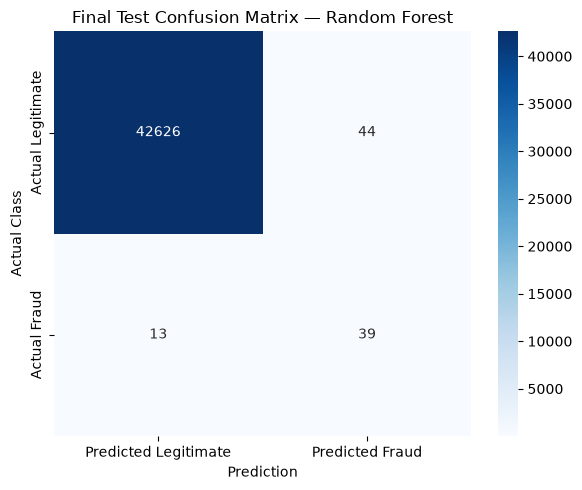

Saved: C:\Users\dell\Desktop\credit-card-fraud-detection\reports\figures\08_final_test_confusion_matrix.png


In [45]:

test_cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Legitimate", "Predicted Fraud"],
    yticklabels=["Actual Legitimate", "Actual Fraud"]
)
plt.title("Final Test Confusion Matrix — Random Forest")
plt.xlabel("Prediction")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "08_final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Saved:", FIGURES_DIR / "08_final_test_confusion_matrix.png")



## 6. Error Analysis

This section examines false negatives (fraudulent transactions classified as legitimate) and false positives (legitimate transactions classified as fraudulent) on the test set. The analysis will compare transaction amounts, time, and anonymized features to identify descriptive patterns in model errors. These observations will be treated as exploratory findings rather than causal explanations.


In [46]:

test_results = test_df.copy()
test_results["Predicted_Class"] = test_predictions
test_results["Fraud_Probability"] = test_probabilities

false_negatives = test_results[
    (test_results["Class"] == 1) &
    (test_results["Predicted_Class"] == 0)
].copy()

false_positives = test_results[
    (test_results["Class"] == 0) &
    (test_results["Predicted_Class"] == 1)
].copy()

true_positives = test_results[
    (test_results["Class"] == 1) &
    (test_results["Predicted_Class"] == 1)
].copy()

print("False negatives (missed fraud):", len(false_negatives))
print("False positives (legitimate transactions flagged):", len(false_positives))
print("True positives (fraud detected):", len(true_positives))


False negatives (missed fraud): 13
False positives (legitimate transactions flagged): 44
True positives (fraud detected): 39


In [47]:

error_amount_summary = pd.DataFrame({
    "Missed Fraud": false_negatives["Amount"].describe(),
    "Detected Fraud": true_positives["Amount"].describe(),
    "False Positives": false_positives["Amount"].describe()
}).round(2)

display(error_amount_summary)


,Missed Fraud,Detected Fraud,False Positives
count,13.00,39.00,44.00
mean,182.49,97.35,836.17
std,333.97,253.73,3872.89
min,0.00,0.00,0.00
25%,3.14,0.77,1.00
50%,12.31,4.69,7.94
75%,187.11,67.81,348.36
max,1096.99,1504.93,25691.16


In [48]:

error_time_summary = pd.DataFrame({
    "Missed Fraud": false_negatives["Time"].describe(),
    "Detected Fraud": true_positives["Time"].describe(),
    "False Positives": false_positives["Time"].describe()
}).round(2)

display(error_time_summary)


,Missed Fraud,Detected Fraud,False Positives
count,13.00,39.00,44.00
mean,160020.92,158023.13,162564.36
std,6209.53,5519.87,4784.82
min,152710.00,151916.00,152752.00
25%,155542.00,154028.00,159719.50
50%,156710.00,155662.00,163416.00
75%,165981.00,160767.50,166262.50
max,170348.00,169966.00,170810.00


In [49]:

feature_columns = [f"V{i}" for i in range(1, 29)]

missed_means = false_negatives[feature_columns].mean()
detected_means = true_positives[feature_columns].mean()

feature_error_comparison = pd.DataFrame({
    "Missed Fraud Mean": missed_means,
    "Detected Fraud Mean": detected_means
})

feature_error_comparison["Absolute Difference"] = (
    feature_error_comparison["Missed Fraud Mean"]
    - feature_error_comparison["Detected Fraud Mean"]
).abs()

top_error_features = feature_error_comparison.sort_values(
    "Absolute Difference", ascending=False
).head(10)

display(top_error_features.round(4))


,Missed Fraud Mean,Detected Fraud Mean,Absolute Difference
V14,-1.0907,-8.5428,7.4520
V12,0.1205,-5.2458,5.3664
V17,0.7580,-3.8509,4.6089
V10,0.0473,-4.1532,4.2005
V3,-1.6210,-5.7622,4.1412
V16,0.4664,-2.6892,3.1556
V2,-0.7116,2.4129,3.1245
V11,0.3295,3.2764,2.9469
V4,1.9282,4.5090,2.5808
V7,-0.0998,-2.4239,2.3241



### Error Analysis Findings

- **Test-set errors:** The selected Random Forest model missed 13 fraudulent transactions and incorrectly flagged 44 legitimate transactions at a threshold of 0.10.
- **Missed fraud amounts:** Missed fraud had a median transaction amount of 12.31, compared with 4.69 for detected fraud. Some missed fraudulent transactions therefore had relatively larger amounts.
- **False-positive amounts:** False positives had a median amount of 7.94 and a mean of 836.17, indicating that a small number of large legitimate transactions influenced the average.
- **Transaction timing:** The median transaction time differed across missed fraud, detected fraud, and false positives. These differences are descriptive and do not establish causality.
- **Feature differences:** V14, V12, V17, V10, and V3 had the largest absolute differences in mean values between missed and detected fraud. Because these variables are anonymized PCA-transformed features, their original business meanings cannot be inferred.
- **Limitation:** This analysis describes errors in one chronological test period. The findings do not guarantee that the same patterns will occur in future transaction data.



## 7. Cost-Sensitive Decision Optimization

This section evaluates how different assumed costs of missed fraud and false positives affect model and threshold selection. A sensitivity analysis will compare candidate models across multiple cost scenarios using validation data only. The costs are illustrative relative units, not actual financial estimates or American Express data. The final decision will reflect the assumptions used and the trade-off between fraud detection and false alarms.


In [50]:

# Validation-only threshold search.
threshold_grid = np.round(np.arange(0.01, 1.00, 0.01), 2)

validation_probabilities = {
    "Logistic Regression": logistic_probabilities,
    "Random Forest": rf_probabilities,
    "XGBoost": xgb_probabilities
}

print("Number of candidate thresholds:", len(threshold_grid))
print("Threshold range:", threshold_grid.min(), "to", threshold_grid.max())
print("Validation fraud cases:", int(y_validation.sum()))


Number of candidate thresholds: 99
Threshold range: 0.01 to 0.99
Validation fraud cases: 56


In [51]:

# Illustrative relative costs only; not actual financial estimates.
missed_fraud_costs = [5, 10, 20, 50]
false_positive_cost = 1

sensitivity_rows = []

for model_name, probabilities in validation_probabilities.items():
    for missed_cost in missed_fraud_costs:
        best_result = None

        for threshold in threshold_grid:
            predictions = (probabilities >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(
                y_validation, predictions, labels=[0, 1]
            ).ravel()

            total_cost = (
                fn * missed_cost
                + fp * false_positive_cost
            )

            result = {
                "Model": model_name,
                "Missed Fraud Cost": missed_cost,
                "False Positive Cost": false_positive_cost,
                "Threshold": threshold,
                "False Positives": fp,
                "Fraud Missed": fn,
                "Fraud Detected": tp,
                "Total Illustrative Cost": total_cost
            }

            if (
                best_result is None
                or result["Total Illustrative Cost"]
                < best_result["Total Illustrative Cost"]
            ):
                best_result = result

        sensitivity_rows.append(best_result)

sensitivity_results = pd.DataFrame(sensitivity_rows)

display(
    sensitivity_results.sort_values(
        ["Missed Fraud Cost", "Total Illustrative Cost"]
    ).round(4).reset_index(drop=True)
)


,Model,Missed Fraud Cost,False Positive Cost,Threshold,False Positives,Fraud Missed,Fraud Detected,Total Illustrative Cost
0,Random Forest,5,1,0.21,6,10,46,56
1,XGBoost,5,1,0.90,1,12,44,61
2,Logistic Regression,5,1,0.98,57,7,49,92
3,Random Forest,10,1,0.11,31,7,49,101
4,XGBoost,10,1,0.90,1,12,44,121
5,Logistic Regression,10,1,0.98,57,7,49,127
6,Random Forest,20,1,0.09,49,6,50,169
7,Logistic Regression,20,1,0.98,57,7,49,197
8,XGBoost,20,1,0.31,46,9,47,226
9,Random Forest,50,1,0.06,86,5,51,336


In [52]:

REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

sensitivity_path = REPORTS_DIR / "cost_sensitivity_analysis.csv"

sensitivity_results.to_csv(sensitivity_path, index=False)

print("Saved sensitivity analysis:", sensitivity_path)


Saved sensitivity analysis: C:\Users\dell\Desktop\credit-card-fraud-detection\reports\cost_sensitivity_analysis.csv


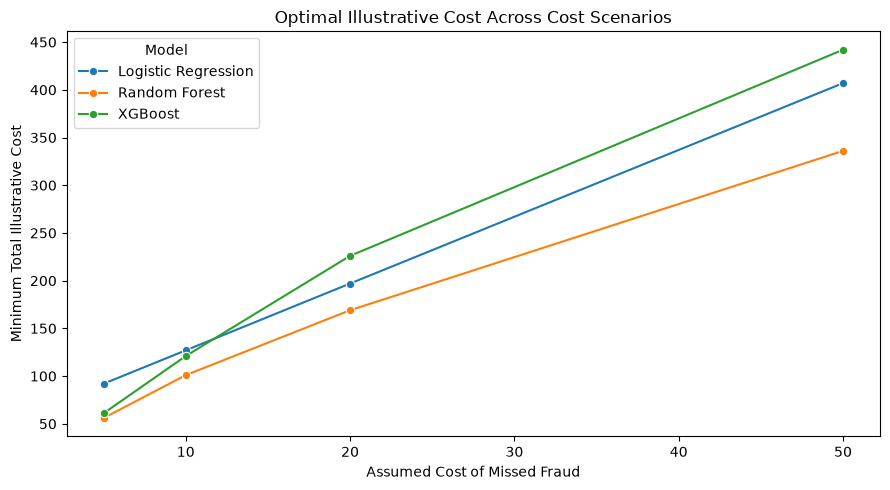

Saved: C:\Users\dell\Desktop\credit-card-fraud-detection\reports\figures\09_cost_sensitivity_analysis.png


In [53]:

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=sensitivity_results,
    x="Missed Fraud Cost",
    y="Total Illustrative Cost",
    hue="Model",
    marker="o"
)

plt.title("Optimal Illustrative Cost Across Cost Scenarios")
plt.xlabel("Assumed Cost of Missed Fraud")
plt.ylabel("Minimum Total Illustrative Cost")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "09_cost_sensitivity_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Saved:", FIGURES_DIR / "09_cost_sensitivity_analysis.png")


In [54]:

import joblib

MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

model_artifact = {
    "model": selected_model,
    "threshold": SELECTED_THRESHOLD,
    "model_name": SELECTED_MODEL_NAME,
    "feature_names": X_train.columns.tolist()
}

model_path = MODELS_DIR / "fraud_random_forest.joblib"
joblib.dump(model_artifact, model_path)

print("Saved model:", model_path)
print("Model:", SELECTED_MODEL_NAME)
print("Threshold:", SELECTED_THRESHOLD)
print("Number of features:", len(X_train.columns))


Saved model: C:\Users\dell\Desktop\credit-card-fraud-detection\models\fraud_random_forest.joblib
Model: Random Forest
Threshold: 0.1
Number of features: 30



## Step 9: Model Monitoring and Operational Analytics

This section tests the monitoring module using a controlled batch of 500 transactions from the test dataset. It generates prediction logs, summarizes fraud-flagging activity, and measures feature-level distribution shifts against the training data. These results demonstrate the monitoring workflow and do not represent live production monitoring.


In [55]:
import sys
from pathlib import Path

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.monitoring import monitor_batch

print("Monitoring module imported successfully.")

Monitoring module imported successfully.


In [56]:
reference_data = X_train.copy()
incoming_data = X_test.iloc[:500].copy()

monitoring_dir = PROJECT_DIR / "reports" / "monitoring"

print("Reference transactions:", len(reference_data))
print("Incoming transactions:", len(incoming_data))
print("Output directory:", monitoring_dir)

Reference transactions: 199364
Incoming transactions: 500
Output directory: C:\Users\dell\Desktop\credit-card-fraud-detection\reports\monitoring


In [57]:
prediction_log, batch_summary, drift_report = monitor_batch(
    reference_data=reference_data,
    incoming_data=incoming_data,
    model=selected_model,
    threshold=SELECTED_THRESHOLD,
    output_dir=monitoring_dir,
)

print("Monitoring completed successfully.")
print("Reports saved to:", monitoring_dir)

Monitoring completed successfully.
Reports saved to: C:\Users\dell\Desktop\credit-card-fraud-detection\reports\monitoring


In [58]:
display(batch_summary)

,monitoring_timestamp_utc,transactions_monitored,transactions_flagged,flagged_transaction_rate,mean_fraud_probability,median_fraud_probability,threshold
0,2026-10-19T08:48:38.357359+00:00,500,0,0.0,0.001235,0.0,0.1


In [59]:
display(
    drift_report.sort_values(
        "psi", ascending=False, na_position="last"
    ).head(10)
)

,feature,psi,warning
0,Time,12.433665,Investigate feature drift
1,V1,1.156371,Investigate feature drift
3,V3,0.872186,Investigate feature drift
28,V28,0.478963,Investigate feature drift
25,V25,0.296119,Investigate feature drift
12,V12,0.279191,Investigate feature drift
15,V15,0.273458,Investigate feature drift
11,V11,0.264060,Investigate feature drift
4,V4,0.174425,No warning
23,V23,0.173050,No warning


In [60]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Get the true labels for the same 500 test transactions.
actual_labels = y_test.iloc[:500].to_numpy()

# Use the predictions already generated by the monitoring module.
predicted_labels = prediction_log["fraud_prediction"].to_numpy()

tn, fp, fn, tp = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=[0, 1],
).ravel()

labelled_batch_metrics = pd.DataFrame([{
    "transactions_evaluated": len(actual_labels),
    "actual_fraud_cases": int(actual_labels.sum()),
    "predicted_fraud_cases": int(predicted_labels.sum()),
    "true_positives": int(tp),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_negatives": int(tn),
    "precision": precision_score(
        actual_labels, predicted_labels, zero_division=0
    ),
    "recall": recall_score(
        actual_labels, predicted_labels, zero_division=0
    ),
    "f1_score": f1_score(
        actual_labels, predicted_labels, zero_division=0
    ),
}])

display(labelled_batch_metrics)

,transactions_evaluated,actual_fraud_cases,predicted_fraud_cases,true_positives,false_positives,false_negatives,true_negatives,precision,recall,f1_score
0,500,0,0,0,0,0,500,0.0,0.0,0.0


In [61]:
labelled_batch_metrics.to_csv(
    monitoring_dir / "labelled_batch_performance.csv",
    index=False,
)

print(
    "Labelled-batch evaluation saved to:",
    monitoring_dir / "labelled_batch_performance.csv",
)

Labelled-batch evaluation saved to: C:\Users\dell\Desktop\credit-card-fraud-detection\reports\monitoring\labelled_batch_performance.csv


In [62]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Evaluate the existing, finalized model on the full held-out test set.
test_scores = selected_model.predict_proba(X_test)[:, 1]
test_predictions = (test_scores >= SELECTED_THRESHOLD).astype(int)
actual_labels = y_test.to_numpy()

tn, fp, fn, tp = confusion_matrix(
    actual_labels,
    test_predictions,
    labels=[0, 1],
).ravel()

full_test_metrics = pd.DataFrame([{
    "transactions_evaluated": len(actual_labels),
    "actual_fraud_cases": int(actual_labels.sum()),
    "predicted_fraud_cases": int(test_predictions.sum()),
    "true_positives": int(tp),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_negatives": int(tn),
    "precision": precision_score(
        actual_labels, test_predictions, zero_division=0
    ),
    "recall": recall_score(
        actual_labels, test_predictions, zero_division=0
    ),
    "f1_score": f1_score(
        actual_labels, test_predictions, zero_division=0
    ),
}])

display(full_test_metrics)

,transactions_evaluated,actual_fraud_cases,predicted_fraud_cases,true_positives,false_positives,false_negatives,true_negatives,precision,recall,f1_score
0,42722,52,83,39,44,13,42626,0.46988,0.75,0.577778


In [63]:
full_test_metrics.to_csv(
    monitoring_dir / "full_test_performance.csv",
    index=False,
)

print(
    "Full test-set performance saved to:",
    monitoring_dir / "full_test_performance.csv",
)

Full test-set performance saved to: C:\Users\dell\Desktop\credit-card-fraud-detection\reports\monitoring\full_test_performance.csv


In [64]:
monitoring_overview = {
    "batch_summary": batch_summary.to_dict(orient="records"),
    "feature_drift_warnings": drift_report[
        drift_report["warning"] == "Investigate feature drift"
    ].to_dict(orient="records"),
    "full_test_performance": full_test_metrics.to_dict(orient="records"),
}

import json

overview_path = monitoring_dir / "monitoring_overview.json"

with open(overview_path, "w", encoding="utf-8") as file:
    json.dump(monitoring_overview, file, indent=2, allow_nan=False)

print("Consolidated monitoring overview saved to:", overview_path)

Consolidated monitoring overview saved to: C:\Users\dell\Desktop\credit-card-fraud-detection\reports\monitoring\monitoring_overview.json



## Step 10: SQL-Based Fraud Analytics and Reporting

This section creates a SQLite database for storing transaction predictions and known fraud outcomes. The database schema is defined in `sql/schema.sql` and will support SQL-based analysis of fraud detection, false positives, missed fraud, and estimated decision costs.


In [65]:
import sqlite3
from pathlib import Path

sql_dir = PROJECT_DIR / "sql"
database_path = PROJECT_DIR / "reports" / "fraud_analytics.db"
schema_path = sql_dir / "schema.sql"

print("Schema file exists:", schema_path.exists())
print("Database path:", database_path)

Schema file exists: True
Database path: C:\Users\dell\Desktop\credit-card-fraud-detection\reports\fraud_analytics.db


In [66]:
schema_sql = schema_path.read_text(encoding="utf-8")

with sqlite3.connect(database_path) as connection:
    connection.executescript(schema_sql)

print("SQLite database created and schema executed successfully.")

SQLite database created and schema executed successfully.


In [67]:
with sqlite3.connect(database_path) as connection:
    tables = pd.read_sql_query(
        """
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
        ORDER BY name;
        """,
        connection,
    )

    columns = pd.read_sql_query(
        "PRAGMA table_info(transaction_predictions);",
        connection,
    )

    indexes = pd.read_sql_query(
        """
        SELECT name
        FROM sqlite_master
        WHERE type = 'index'
          AND tbl_name = 'transaction_predictions'
        ORDER BY name;
        """,
        connection,
    )

print("Tables:")
display(tables)

print("Transaction table columns:")
display(columns)

print("Indexes:")
display(indexes)

Tables:


,name
0,sqlite_sequence
1,transaction_predictions


Transaction table columns:


,cid,name,type,notnull,dflt_value,pk
0,0,prediction_id,INTEGER,0,None,1
1,1,transaction_time,REAL,1,None,0
2,2,transaction_amount,REAL,1,None,0
3,3,fraud_probability,REAL,1,None,0
4,4,decision_threshold,REAL,1,None,0
5,5,predicted_fraud,INTEGER,1,None,0
6,6,actual_fraud,INTEGER,0,None,0
7,7,prediction_timestamp_utc,TEXT,1,None,0
8,8,model_name,TEXT,1,None,0


Indexes:


,name
0,idx_predictions_actual_fraud
1,idx_predictions_predicted_fraud
2,idx_predictions_timestamp
3,idx_predictions_transaction_time


In [68]:
# Generate scores and predictions for the full test set.
sql_test_scores = selected_model.predict_proba(X_test)[:, 1]
sql_test_predictions = (
    sql_test_scores >= SELECTED_THRESHOLD
).astype(int)

# Prepare the records required by the SQL table.
sql_prediction_records = pd.DataFrame({
    "transaction_time": X_test["Time"].to_numpy(),
    "transaction_amount": X_test["Amount"].to_numpy(),
    "fraud_probability": sql_test_scores,
    "decision_threshold": SELECTED_THRESHOLD,
    "predicted_fraud": sql_test_predictions,
    "actual_fraud": y_test.to_numpy(),
    "prediction_timestamp_utc": (
        pd.Timestamp.now(tz="UTC").isoformat()
    ),
    "model_name": SELECTED_MODEL_NAME,
})

print("Records prepared:", len(sql_prediction_records))
display(sql_prediction_records.head())

Records prepared: 42722


,transaction_time,transaction_amount,fraud_probability,decision_threshold,predicted_fraud,actual_fraud,prediction_timestamp_utc,model_name
0,151328.0,41.95,0.0,0.1,0,0,2026-10-19T08:54:54.705468+00:00,Random Forest
1,151329.0,1.79,0.0,0.1,0,0,2026-10-19T08:54:54.705468+00:00,Random Forest
2,151332.0,1.79,0.0,0.1,0,0,2026-10-19T08:54:54.705468+00:00,Random Forest
3,151333.0,16.99,0.0,0.1,0,0,2026-10-19T08:54:54.705468+00:00,Random Forest
4,151333.0,55.28,0.0,0.1,0,0,2026-10-19T08:54:54.705468+00:00,Random Forest


In [69]:
with sqlite3.connect(database_path) as connection:
    sql_prediction_records.to_sql(
        "transaction_predictions",
        connection,
        if_exists="append",
        index=False,
    )

print("Test-set prediction records inserted successfully.")

Test-set prediction records inserted successfully.


In [70]:
with sqlite3.connect(database_path) as connection:
    database_summary = pd.read_sql_query(
        """
        SELECT
            COUNT(*) AS total_transactions,
            SUM(actual_fraud) AS actual_fraud_cases,
            SUM(predicted_fraud) AS predicted_fraud_cases,
            SUM(
                CASE
                    WHEN actual_fraud = 1 AND predicted_fraud = 1
                    THEN 1 ELSE 0
                END
            ) AS true_positives,
            SUM(
                CASE
                    WHEN actual_fraud = 0 AND predicted_fraud = 1
                    THEN 1 ELSE 0
                END
            ) AS false_positives,
            SUM(
                CASE
                    WHEN actual_fraud = 1 AND predicted_fraud = 0
                    THEN 1 ELSE 0
                END
            ) AS false_negatives
        FROM transaction_predictions;
        """,
        connection,
    )

display(database_summary)

,total_transactions,actual_fraud_cases,predicted_fraud_cases,true_positives,false_positives,false_negatives
0,42722,52,83,39,44,13


In [71]:
sql_file_path = sql_dir / "fraud_analytics.sql"

analytics_sql = sql_file_path.read_text(encoding="utf-8")
sql_queries = [
    query.strip()
    for query in analytics_sql.split(";")
    if query.strip()
]

print("SQL file found:", sql_file_path.exists())
print("Number of queries loaded:", len(sql_queries))

SQL file found: True
Number of queries loaded: 6


In [75]:
import re
import sqlite3
import pandas as pd

# Read the saved SQL file.
analytics_sql = sql_file_path.read_text(encoding="utf-8")

# Extract each numbered query, excluding the comments before Query 1.
query_blocks = re.split(
    r"-- Query \d+:.*\n",
    analytics_sql
)

sql_queries = [
    block.strip()
    for block in query_blocks[1:]
    if block.strip()
]

print("Number of queries identified:", len(sql_queries))

sql_results = {}

with sqlite3.connect(database_path) as connection:
    for query_number, query in enumerate(sql_queries, start=1):
        # Remove any remaining full-line SQL comments.
        clean_lines = [
            line for line in query.splitlines()
            if not line.strip().startswith("--")
        ]
        clean_query = "\n".join(clean_lines).strip()

        if not clean_query:
            continue

        result = pd.read_sql_query(clean_query, connection)
        sql_results[f"query_{query_number}"] = result

        print(f"\nQuery {query_number} results:")
        display(result)

print("\nTotal analytical queries executed:", len(sql_results))

Number of queries identified: 5

Query 1 results:


,total_transactions,actual_fraud_cases,flagged_transactions,true_positives,false_positives,false_negatives,precision,recall
0,42722,52,83,39,44,13,0.4699,0.75



Query 2 results:


,actual_fraud,predicted_fraud,transaction_count
0,0,0,42626
1,0,1,44
2,1,0,13
3,1,1,39



Query 3 results:


...


Query 4 results:


,false_negatives,false_positives,estimated_decision_cost_units
0,13,44,174.0



Query 5 results:


,actual_fraud,transaction_count,mean_fraud_probability,minimum_fraud_probability,maximum_fraud_probability
0,0,42670,0.001227,0.0,0.694230
1,1,52,0.663849,0.0,0.984714



Total analytical queries executed: 5


In [76]:
sql_results_dir = PROJECT_DIR / "reports" / "sql"
sql_results_dir.mkdir(parents=True, exist_ok=True)

for query_name, result in sql_results.items():
    result.to_csv(
        sql_results_dir / f"{query_name}.csv",
        index=False,
    )

print("Saved SQL reports to:", sql_results_dir)
print("Reports created:", len(sql_results))

Saved SQL reports to: C:\Users\dell\Desktop\credit-card-fraud-detection\reports\sql
Reports created: 5


In [77]:
# Verify the saved SQL reports.
saved_reports = sorted(sql_results_dir.glob("query_*.csv"))

print("Number of saved SQL reports:", len(saved_reports))
for report in saved_reports:
    print("-", report.name)

# Verify the database record count.
with sqlite3.connect(database_path) as connection:
    record_count = pd.read_sql_query(
        "SELECT COUNT(*) AS total_records FROM transaction_predictions;",
        connection,
    ).iloc[0, 0]

print("\nTotal database records:", record_count)

assert len(saved_reports) == 5, "Expected five SQL reports."
assert record_count == len(X_test), "Database record count does not match the test set."

print("All SQL deliverables verified successfully.")

Number of saved SQL reports: 5
- query_1.csv
- query_2.csv
- query_3.csv
- query_4.csv
- query_5.csv

Total database records: 42722
All SQL deliverables verified successfully.



## Final Packaging: Project Structure Audit

This section reviews the project directory, checks the expected folders and key deliverables, and identifies missing files before preparing the repository for GitHub publication. No files will be modified or deleted during this audit.


In [79]:
from pathlib import Path

for folder in sorted(PROJECT_DIR.iterdir()):
    if folder.is_dir():
        print(f"\n[{folder.name}/]")

        for item in sorted(folder.iterdir()):
            if item.is_file():
                size_mb = item.stat().st_size / (1024 * 1024)
                print(f"  {item.name} ({size_mb:.2f} MB)")
            elif item.is_dir():
                print(f"  {item.name}/")
    else:
        size_mb = folder.stat().st_size / (1024 * 1024)
        print(f"{folder.name} ({size_mb:.2f} MB)")


[.ipynb_checkpoints/]
  fraud_detection_api-checkpoint.py (0.00 MB)

[.pytest_cache/]
  .gitignore (0.00 MB)
  CACHEDIR.TAG (0.00 MB)
  README.md (0.00 MB)
  v/

[api/]
  .ipynb_checkpoints/
  __pycache__/
  fraud_detection_api.py (0.00 MB)
  README.md (0.00 MB)

[data/]
  creditcard.csv (143.84 MB)
fraud_detection_api.py (0.00 MB)

[models/]
  fraud_random_forest.joblib (6.88 MB)

[notebooks/]
  .ipynb_checkpoints/
  01_data_audit.ipynb (0.54 MB)

[reports/]
  cost_sensitivity_analysis.csv (0.00 MB)
  figures/
  fraud_analytics.db (6.45 MB)
  monitoring/
  sql/

[sql/]
  .ipynb_checkpoints/
  fraud_analytics.sql (0.00 MB)
  schema.sql (0.00 MB)

[src/]
  .ipynb_checkpoints/
  __pycache__/
  monitoring.py (0.00 MB)

[tests/]
  .ipynb_checkpoints/
  __pycache__/
  test_fraud_detection_api.py (0.00 MB)


In [80]:
expected_paths = [
    "data",
    "notebooks",
    "notebooks/01_data_audit.ipynb",
    "src",
    "src/monitoring.py",
    "api",
    "api/fraud_detection_api.py",
    "api/README.md",
    "sql",
    "sql/schema.sql",
    "sql/fraud_analytics.sql",
    "tests/test_fraud_detection_api.py",
    "models/fraud_random_forest.joblib",
    "reports/figures",
    "reports/monitoring",
    "reports/sql",
    "reports/fraud_analytics.db",
]

audit_results = pd.DataFrame([
    {
        "path": path,
        "exists": (PROJECT_DIR / path).exists(),
        "type": (
            "Folder" if (PROJECT_DIR / path).is_dir()
            else "File" if (PROJECT_DIR / path).is_file()
            else "Missing"
        ),
    }
    for path in expected_paths
])

display(audit_results)

,path,exists,type
0,data,True,Folder
1,notebooks,True,Folder
2,notebooks/01_data_audit.ipynb,True,File
3,src,True,Folder
4,src/monitoring.py,True,File
5,api,True,Folder
6,api/fraud_detection_api.py,True,File
7,api/README.md,True,File
8,sql,True,Folder
9,sql/schema.sql,True,File


In [81]:
missing_items = audit_results.loc[
    ~audit_results["exists"], ["path"]
]

if missing_items.empty:
    print("All checked deliverables exist.")
else:
    print("Items requiring review:")
    display(missing_items)

All checked deliverables exist.


In [82]:
print("MONITORING REPORTS")
monitoring_dir = PROJECT_DIR / "reports" / "monitoring"

for item in sorted(monitoring_dir.iterdir()):
    if item.is_file():
        print(f"{item.name} ({item.stat().st_size / 1024:.1f} KB)")

print("\nSQL REPORTS")
sql_results_dir = PROJECT_DIR / "reports" / "sql"

for item in sorted(sql_results_dir.iterdir()):
    if item.is_file():
        print(f"{item.name} ({item.stat().st_size / 1024:.1f} KB)")

print("\nROOT-LEVEL FILES")
for item in sorted(PROJECT_DIR.iterdir()):
    if item.is_file():
        print(f"{item.name} ({item.stat().st_size / 1024:.1f} KB)")

MONITORING REPORTS
batch_summary.csv (0.2 KB)
feature_drift_report.csv (1.2 KB)
full_test_performance.csv (0.2 KB)
labelled_batch_performance.csv (0.2 KB)
monitoring_overview.json (1.7 KB)
prediction_log.csv (25.8 KB)

SQL REPORTS
query_1.csv (0.2 KB)
query_2.csv (0.1 KB)
query_3.csv (0.2 KB)
query_4.csv (0.1 KB)
query_5.csv (0.2 KB)

ROOT-LEVEL FILES
fraud_detection_api.py (2.3 KB)


In [83]:
important_files = [
    "README.md",
    "requirements.txt",
    "environment.yml",
    ".gitignore",
    "src/__init__.py",
]

for relative_path in important_files:
    path = PROJECT_DIR / relative_path
    print(f"{relative_path}: {'Exists' if path.exists() else 'Missing'}")

README.md: Missing
requirements.txt: Missing
environment.yml: Missing
.gitignore: Missing
src/__init__.py: Missing


In [84]:
from pathlib import Path
import hashlib

root_api = PROJECT_DIR / "fraud_detection_api.py"
working_api = PROJECT_DIR / "api" / "fraud_detection_api.py"

def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

print("Root API exists:", root_api.exists())
print("Working API exists:", working_api.exists())

if root_api.exists() and working_api.exists():
    print("Root API size:", root_api.stat().st_size, "bytes")
    print("Working API size:", working_api.stat().st_size, "bytes")
    print("Files are identical:", file_hash(root_api) == file_hash(working_api))

    print("\n--- Root-level API contents ---")
    print(root_api.read_text(encoding="utf-8"))

Root API exists: True
Working API exists: True
Root API size: 2355 bytes
Working API size: 2355 bytes
Files are identical: True

--- Root-level API contents ---

from pathlib import Path
from typing import Dict

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field


# Locate the project and saved model
PROJECT_DIR = Path(__file__).resolve().parent.parent
MODEL_PATH = PROJECT_DIR / "models" / "fraud_random_forest.joblib"

# Load the trained model and metadata
artifact = joblib.load(MODEL_PATH)

model = artifact["model"]
threshold = artifact["threshold"]
feature_names = artifact["feature_names"]

# Initialize the API
app = FastAPI(
    title="Credit Card Fraud Detection API",
    description="Fraud probability and classification using a trained Random Forest model.",
    version="1.0.0"
)


# Define the expected request structure
class Transaction(BaseModel):
    features: Dict[str, float] = Field(
        ...,
        descrip